In [1]:
import pandas as pd

# Carregar os datasets
movies = pd.read_csv('movies (1).csv')
users = pd.read_csv('users.csv')
ratings = pd.read_csv('ratings (1).csv')

# Exibir as primeiras linhas dos datasets para verificar a estrutura
movies.head(), users.head(), ratings.head()


(   MovieID                               Title                        Genres
 0        1                    Toy Story (1995)   Animation|Children's|Comedy
 1        2                      Jumanji (1995)  Adventure|Children's|Fantasy
 2        3             Grumpier Old Men (1995)                Comedy|Romance
 3        4            Waiting to Exhale (1995)                  Comedy|Drama
 4        5  Father of the Bride Part II (1995)                        Comedy,
    UserID Gender  Age  Occupation Zip-code
 0       1      F    1          10    48067
 1       2      M   56          16    70072
 2       3      M   25          15    55117
 3       4      M   45           7    02460
 4       5      M   25          20    55455,
    UserID  MovieID  Rating  Timestamp
 0       1     1193       5  978300760
 1       1      661       3  978302109
 2       1      914       3  978301968
 3       1     3408       4  978300275
 4       1     2355       5  978824291)

pre-processamento

## Pré-processamento dos Dados

Antes de realizar qualquer análise, é importante realizar o pré-processamento dos dados para garantir que eles estejam limpos e prontos para uso. Vamos realizar algumas etapas comuns de pré-processamento, como:

1. Verificar e tratar valores ausentes.
2. Converter tipos de dados, se necessário.
3. Criar novas colunas úteis para análise.
4. Remover duplicatas, se houver.

In [2]:
# Verificar informações dos datasets
movies_info = movies.info()
users_info = users.info()
ratings_info = ratings.info()

# Verificar valores ausentes
missing_movies = movies.isnull().sum()
missing_users = users.isnull().sum()
missing_ratings = ratings.isnull().sum()

# Verificar valores duplicados
duplicates_movies = movies.duplicated().sum()
duplicates_users = users.duplicated().sum()
duplicates_ratings = ratings.duplicated().sum()

# Resultado consolidado
preprocessing_summary = {
    "missing_values": {
        "movies": missing_movies.to_dict(),
        "users": missing_users.to_dict(),
        "ratings": missing_ratings.to_dict()
    },
    "duplicates": {
        "movies": duplicates_movies,
        "users": duplicates_users,
        "ratings": duplicates_ratings
    }
}

preprocessing_summary


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-

{'missing_values': {'movies': {'MovieID': 0, 'Title': 0, 'Genres': 0},
  'users': {'UserID': 0,
   'Gender': 0,
   'Age': 0,
   'Occupation': 0,
   'Zip-code': 0},
  'ratings': {'UserID': 0, 'MovieID': 0, 'Rating': 0, 'Timestamp': 0}},
 'duplicates': {'movies': 0, 'users': 0, 'ratings': 0}}

## Análise Exploratória dos Dados

A análise exploratória de dados (EDA) é uma etapa crucial no processo de análise de dados, pois nos permite entender melhor as características dos dados e identificar padrões, tendências e anomalias. Nesta seção, vamos realizar algumas análises exploratórias nos datasets disponíveis:

1. **Distribuição de Gêneros de Filmes**: Vamos visualizar a distribuição dos gêneros de filmes para entender quais são os mais comuns.
2. **Distribuição de Idades dos Usuários**: Vamos analisar a distribuição etária dos usuários para identificar o perfil demográfico.
3. **Distribuição de Avaliações**: Vamos observar como as avaliações estão distribuídas para entender a tendência de avaliação dos usuários.

Vamos começar com a análise da distribuição de gêneros de filmes.

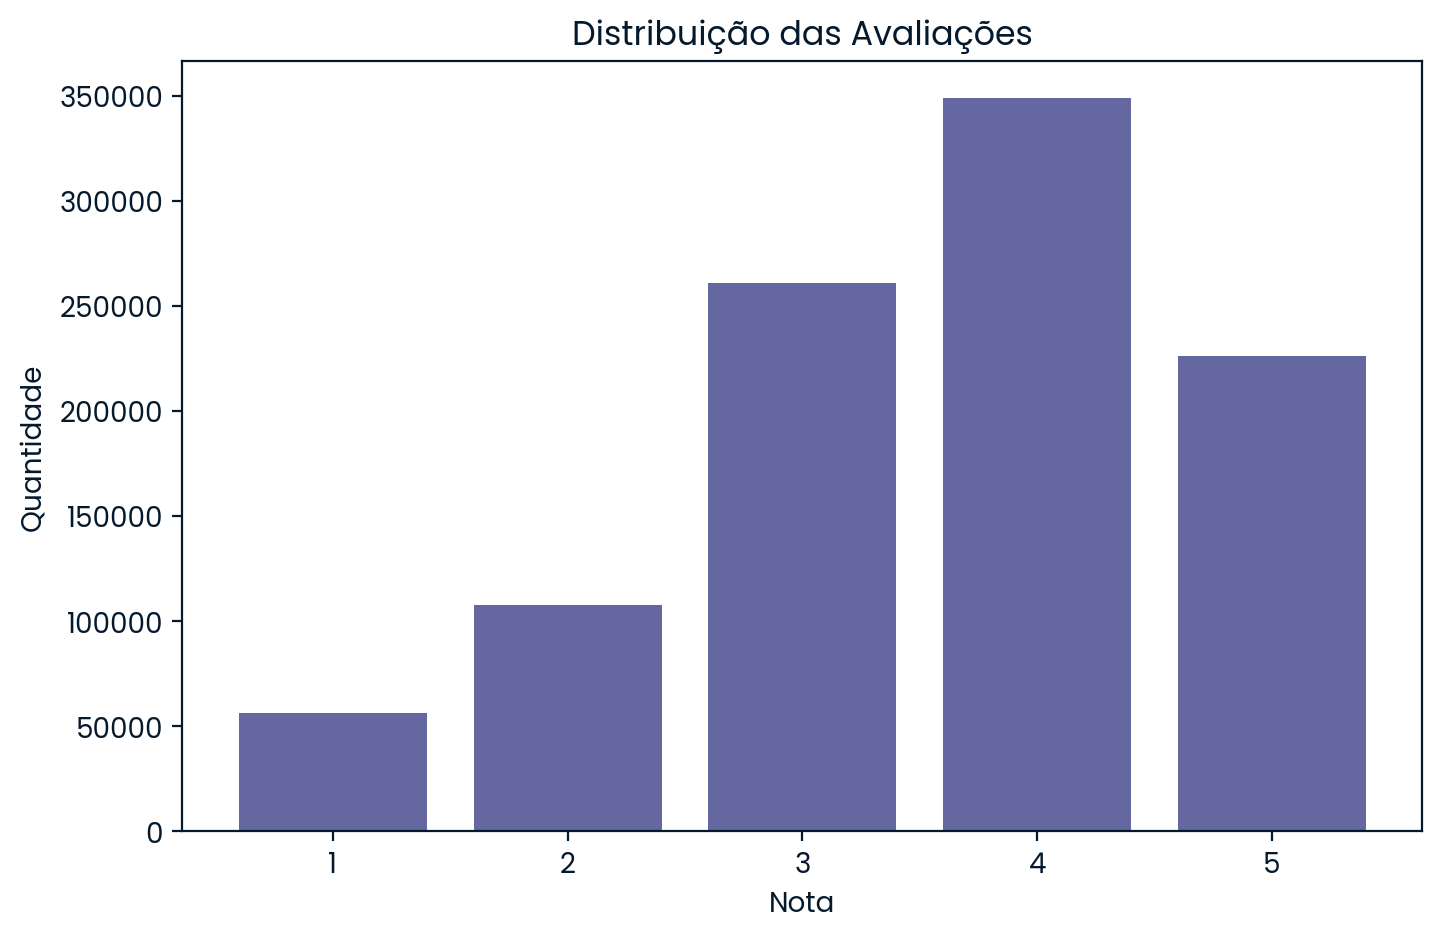

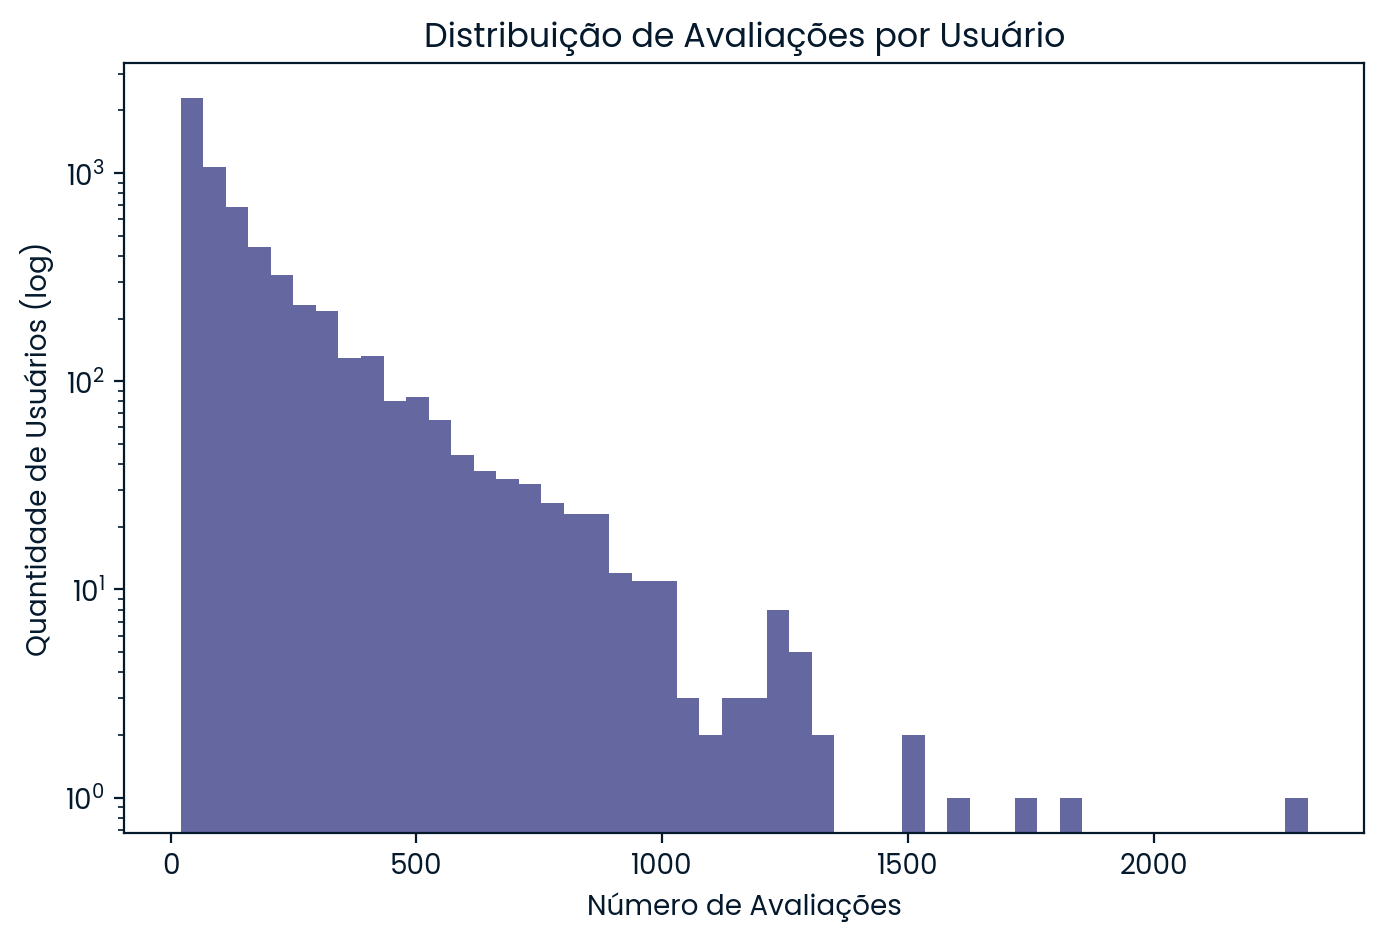

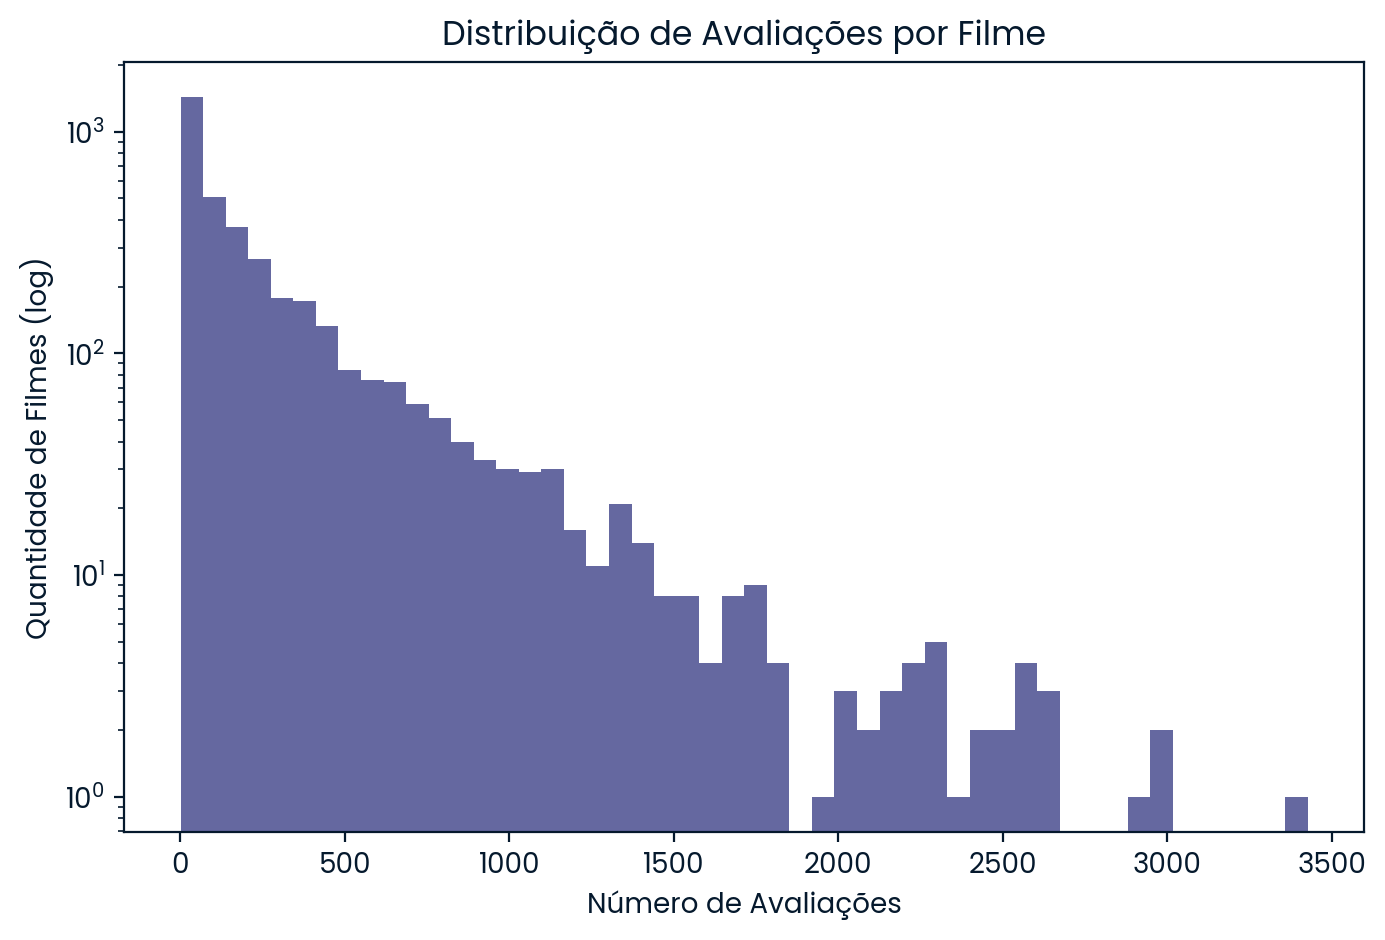

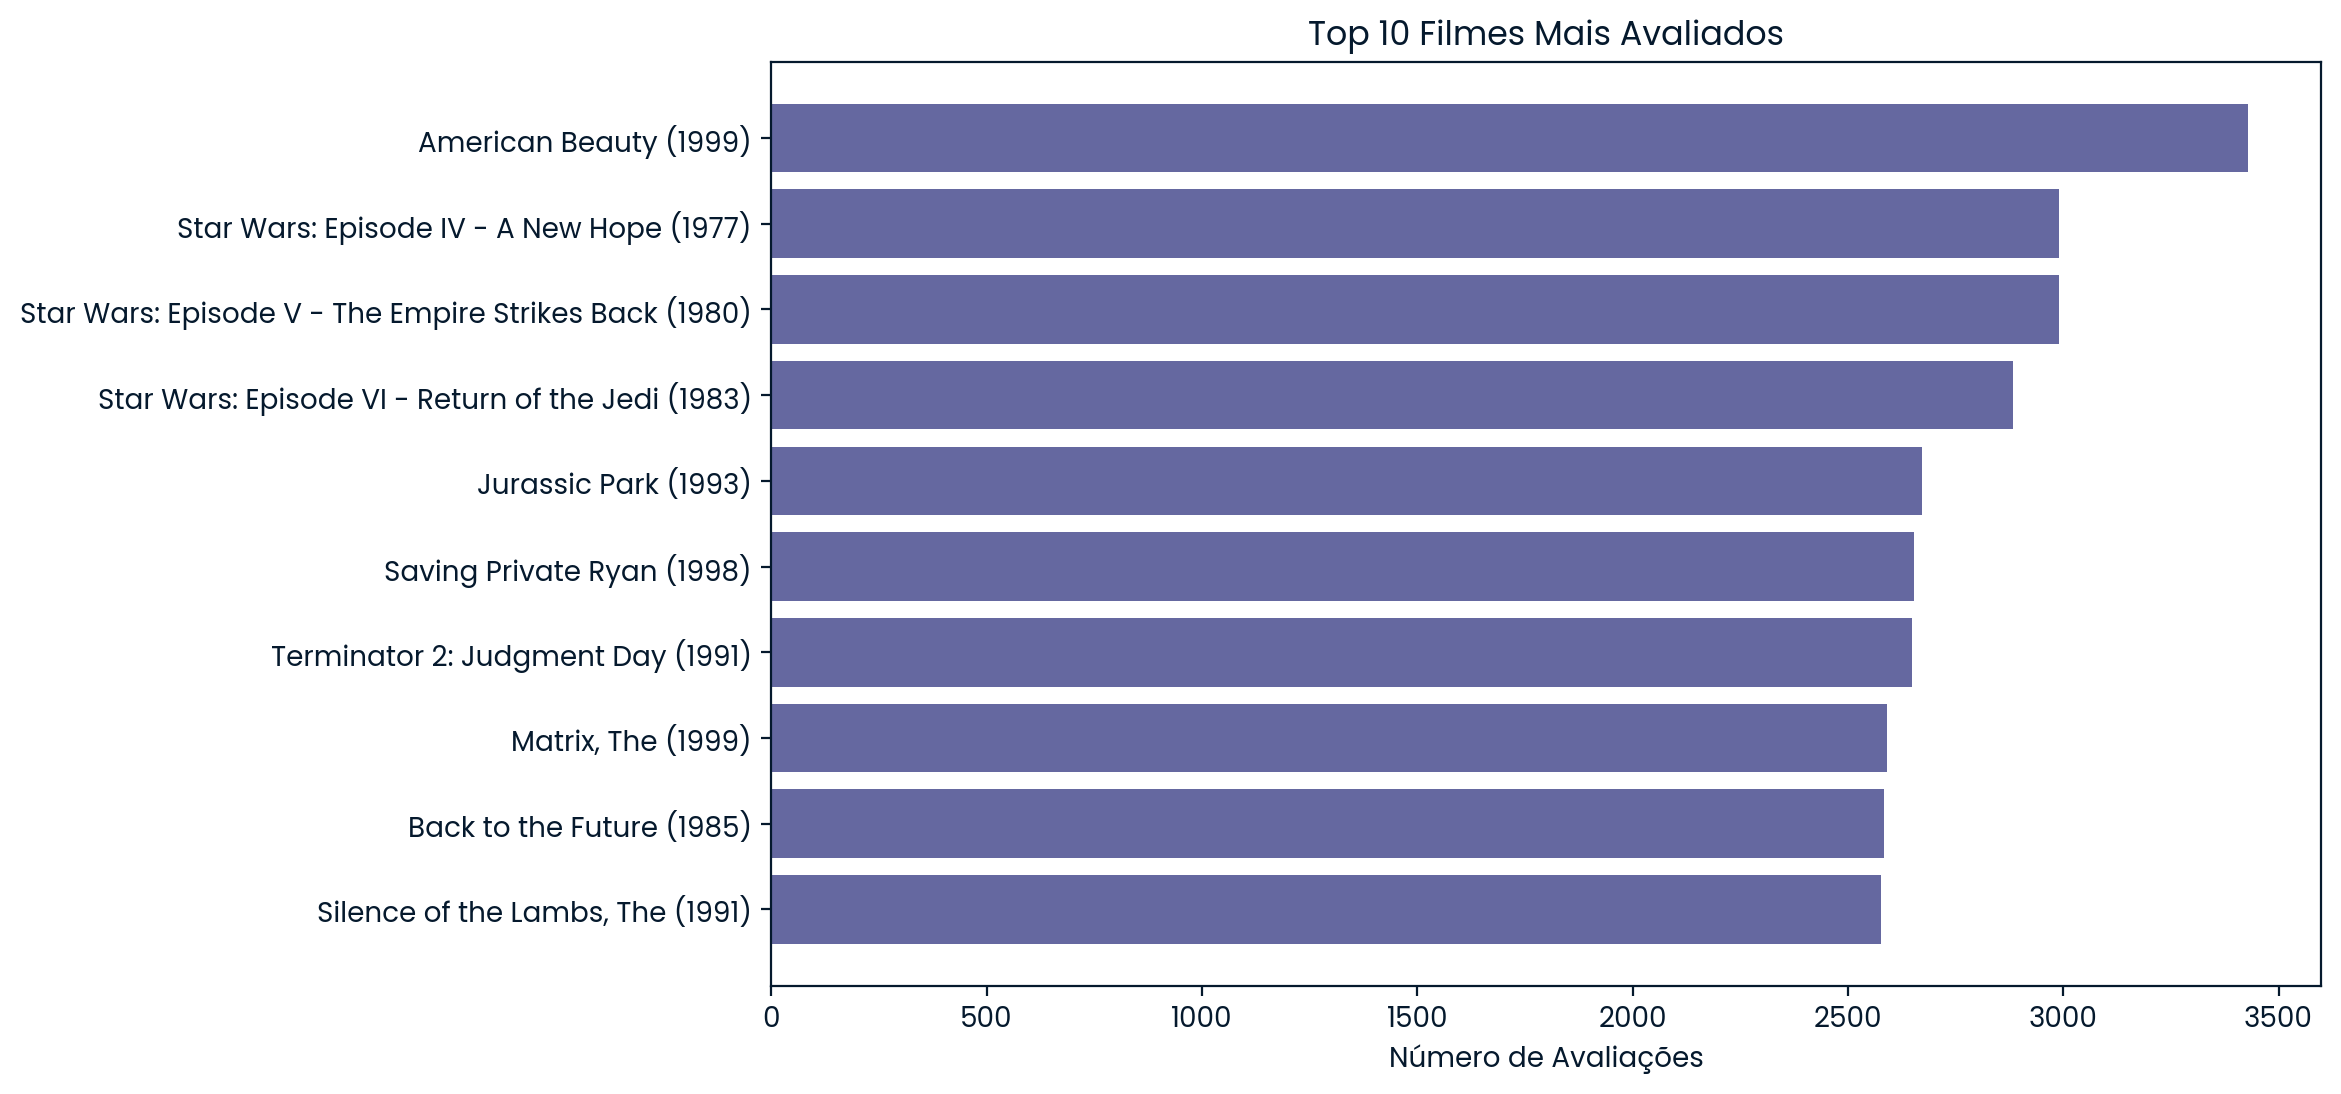

{'Total de usuários': 6040,
 'Total de filmes': 3883,
 'Total de avaliações': 1000209,
 'Média de avaliações por usuário': 165.6,
 'Média de avaliações por filme': 269.89}

In [3]:
import matplotlib.pyplot as plt

# 1. Quantidade de avaliações por nota
rating_counts = ratings['Rating'].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(rating_counts.index, rating_counts.values)
plt.title('Distribuição das Avaliações')
plt.xlabel('Nota')
plt.ylabel('Quantidade')
plt.xticks(rating_counts.index)
plt.show()

# 2. Número de avaliações por usuário
ratings_per_user = ratings.groupby('UserID').size()

plt.figure(figsize=(8,5))
plt.hist(ratings_per_user, bins=50, log=True)
plt.title('Distribuição de Avaliações por Usuário')
plt.xlabel('Número de Avaliações')
plt.ylabel('Quantidade de Usuários (log)')
plt.show()

# 3. Número de avaliações por filme
ratings_per_movie = ratings.groupby('MovieID').size()

plt.figure(figsize=(8,5))
plt.hist(ratings_per_movie, bins=50, log=True)
plt.title('Distribuição de Avaliações por Filme')
plt.xlabel('Número de Avaliações')
plt.ylabel('Quantidade de Filmes (log)')
plt.show()

# 4. Top 10 filmes mais avaliados
top_movies = ratings_per_movie.sort_values(ascending=False).head(10)
top_movies = top_movies.reset_index().merge(movies, on='MovieID')

plt.figure(figsize=(10,6))
plt.barh(top_movies['Title'], top_movies[0])
plt.xlabel('Número de Avaliações')
plt.title('Top 10 Filmes Mais Avaliados')
plt.gca().invert_yaxis()
plt.show()

# 5. Estatísticas gerais
stats = {
    'Total de usuários': users['UserID'].nunique(),
    'Total de filmes': movies['MovieID'].nunique(),
    'Total de avaliações': ratings.shape[0],
    'Média de avaliações por usuário': round(ratings_per_user.mean(), 2),
    'Média de avaliações por filme': round(ratings_per_movie.mean(), 2)
}

stats


## Análise Exploratória dos Dados MovieLens
###  Estatísticas Gerais
-Total de usuários: 6.040
 
- Total de filmes: 3.883
 
- Total de avaliações: 1.000.209
 
- Média de avaliações por usuário: 165,6
  
- Média de avaliações por filme: 269,89

### Principais Insights dos Gráficos
1. Distribuição das Notas:A maioria das notas está concentrada em 4 e 5, indicando uma tendência dos usuários darem avaliações mais altas.
 
2. Distribuição de Avaliações por Usuário:A maior parte dos usuários avalia poucos filmes, enquanto poucos usuários são altamente ativos.
 
3. Distribuição de Avaliações por Filme:A maioria dos filmes possui poucas avaliações, enquanto poucos filmes são muito populares.
 
4. Top 10 Filmes Mais Avaliados:Os filmes mais populares são aqueles que tendem a ser mais conhecidos no mercado, como American Beauty (1999), Star Wars (1977), entre outros.

## Matriz de Interações

A matriz de interações é uma representação dos dados de avaliações, onde as linhas representam os usuários e as colunas representam os filmes. Cada célula na matriz contém a avaliação que um usuário deu a um filme específico. Essa matriz é útil para análises de filtragem colaborativa e sistemas de recomendação.

In [4]:
from scipy.sparse import csr_matrix

# Construindo a matriz de interações (usuário x filme) usando as avaliações como valores
interaction_matrix = ratings.pivot_table(
    index='UserID',
    columns='MovieID',
    values='Rating'
).fillna(0)

# Converter para formato esparso para otimizar memória
interaction_sparse = csr_matrix(interaction_matrix.values)

# Mostrar a dimensão da matriz
interaction_shape = interaction_matrix.shape

interaction_shape, interaction_matrix.head()


((6040, 3706),
 MovieID  1     2     3     4     5     6     ...  3947  3948  3949  3950  3951  3952
 UserID                                       ...                                    
 1         5.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   0.0   0.0   0.0   0.0   0.0
 2         0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   0.0   0.0   0.0   0.0   0.0
 3         0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   0.0   0.0   0.0   0.0   0.0
 4         0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   0.0   0.0   0.0   0.0   0.0
 5         0.0   0.0   0.0   0.0   0.0   2.0  ...   0.0   0.0   0.0   0.0   0.0   0.0
 
 [5 rows x 3706 columns])

##  Filtragem Colaborativa

###  Matrix Factorization (SVD/ALS):

 Matrix Factorization (SVD/ALS) é a melhor escolha. Funciona muito bem no MovieLens

In [5]:
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD

# Definir o modelo SVD
svd = TruncatedSVD(n_components=20, random_state=42)
svd_matrix = svd.fit_transform(interaction_sparse)

# Função para gerar recomendações com SVD
def recommend_movies_svd(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix[user_index]

    scores = np.dot(svd.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    recommendations = pd.DataFrame({
        'MovieID': movie_ids,
        'Score': scores
    })

    # Remover filmes que o usuário já assistiu
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    recommendations = recommendations[~recommendations['MovieID'].isin(watched)]

    # Top N recomendações
    top_recommendations = recommendations.sort_values(by='Score', ascending=False).head(n_recommendations)

    # Obter os títulos dos filmes
    top_recommendations = top_recommendations.merge(movies, on='MovieID')

    return top_recommendations[['Title', 'Genres', 'Score']]

# Testar para usuário 1
svd_recommendations_user1 = recommend_movies_svd(user_id=1, n_recommendations=10)

svd_recommendations_user1

,Title,Genres,Score
0,"Lion King, The (1994)",Animation|Children's|Musical,2.608700
1,"Shawshank Redemption, The (1994)",Drama,2.171291
2,Babe (1995),Children's|Comedy|Drama,2.104139
3,"Silence of the Lambs, The (1991)",Drama|Thriller,1.913071
4,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,1.903917
5,Fantasia (1940),Animation|Children's|Musical,1.735207
6,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,1.591992
7,Peter Pan (1953),Animation|Children's|Fantasy|Musical,1.562925
8,Sleeping Beauty (1959),Animation|Children's|Musical,1.532199
9,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,1.501439


### Ajustar hiperparâmetros do SVD/ALS para melhor performance

Procedimento para tuning (SVD com scikit-learn ou Surprise):

1. Definir faixa de valores para n_components.
 
2. Avaliar com Cross-Validation (ex.: RMSE, MAE).
 
3. Escolher menor erro e testar generalização.

In [6]:
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
import numpy as np

# Definir faixas de valores para n_components
components_range = [10, 20, 50, 100]

# Preparar K-Fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Guardar resultados
results = []

for n_comp in components_range:
    rmses = []

    for train_idx, test_idx in kf.split(interaction_sparse):
        train_data = interaction_sparse[train_idx]
        test_data = interaction_sparse[test_idx]

        svd = TruncatedSVD(n_components=n_comp, random_state=42)
        svd.fit(train_data)

        reconstructed = svd.inverse_transform(svd.transform(test_data))
        true = test_data.toarray()

        # Calcular RMSE considerando apenas os elementos que existem no test_data
        mask = true != 0
        mse = mean_squared_error(true[mask], reconstructed[mask])
        rmse = np.sqrt(mse)
        rmses.append(rmse)

    results.append({'n_components': n_comp, 'RMSE médio': np.mean(rmses)})

# Transformar resultados em dataframe
results_df = pd.DataFrame(results).sort_values('RMSE médio')

results_df

,n_components,RMSE médio
3,100,2.175307
2,50,2.294589
1,20,2.440817
0,10,2.554672


###  Conclusão:
→ 100 componentes apresentou o menor RMSE, indicando melhor performance no balanceamento entre captura de padrões e erro de reconstrução.

In [7]:
# Aplicar SVD otimizado com 100 componentes
svd_optimized = TruncatedSVD(n_components=100, random_state=42)
svd_matrix_optimized = svd_optimized.fit_transform(interaction_sparse)

# Função para gerar recomendações usando o SVD otimizado
def recommend_movies_svd_optimized(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]

    scores = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    recommendations = pd.DataFrame({
        'MovieID': movie_ids,
        'Score': scores
    })

    # Remover filmes que o usuário já assistiu
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    recommendations = recommendations[~recommendations['MovieID'].isin(watched)]

    # Top N recomendações
    top_recommendations = recommendations.sort_values(by='Score', ascending=False).head(n_recommendations)

    # Obter os títulos dos filmes
    top_recommendations = top_recommendations.merge(movies, on='MovieID')

    return top_recommendations[['Title', 'Genres', 'Score']]

# Gerar recomendações para o usuário 1
svd_optimized_recommendations_user1 = recommend_movies_svd_optimized(user_id=1, n_recommendations=10)
svd_optimized_recommendations_user1

,Title,Genres,Score
0,"Lion King, The (1994)",Animation|Children's|Musical,3.464555
1,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,2.283371
2,Fantasia (1940),Animation|Children's|Musical,2.113384
3,Ghostbusters (1984),Comedy|Horror,1.927834
4,Sleeping Beauty (1959),Animation|Children's|Musical,1.725836
5,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,1.710751
6,Peter Pan (1953),Animation|Children's|Fantasy|Musical,1.705988
7,"Green Mile, The (1999)",Drama|Thriller,1.569269
8,Alice in Wonderland (1951),Animation|Children's|Musical,1.552391
9,Pinocchio (1940),Animation|Children's,1.483890


### Tuning avançado:
O TruncatedSVD (sklearn) possui poucos hiperparâmetros. Para tuning avançado e modelos realmente robustos de fatoração de matrizes, recomendamos utilizar bibliotecas específicas de recomendação como:

 Surprise (SVD, SVD++) → suporte a regularização, taxa de aprendizado, número de épocas (iterations).

In [ ]:
pip install scikit-surprise

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


 SVD com Surprise

In [10]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import GridSearchCV

# Preparar os dados
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings[['UserID', 'MovieID', 'Rating']], reader)

# Definir grid de hiperparâmetros
param_grid = {
    'n_factors': [50, 100, 150],
    'lr_all': [0.002, 0.005, 0.01],
    'reg_all': [0.02, 0.05, 0.1],
    'n_epochs': [20, 50, 70]
}

# Grid Search
gs = GridSearchCV(SVD, param_grid, measures=['rmse'], cv=3, n_jobs=-1)
gs.fit(data)

# Resultado
print(f"Melhores parâmetros: {gs.best_params['rmse']}")
print(f"Melhor RMSE: {gs.best_score['rmse']}")

# Treinar modelo final
best_model = gs.best_estimator['rmse']
best_model.fit(data.build_full_trainset())


Melhores parâmetros: {'n_factors': 150, 'lr_all': 0.005, 'reg_all': 0.05, 'n_epochs': 50}
Melhor RMSE: 0.8635493924120969


In [11]:
# Função de recomendação
def recommend_movies_surprise(user_id, n_recommendations=10):
    trainset = data.build_full_trainset()
    all_movie_ids = trainset._raw2inner_id_items.keys()

    user_watched = set([j for (j, _) in trainset.ur[trainset.to_inner_uid(user_id)]])

    predictions = []
    for movie_id in all_movie_ids:
        if trainset.to_inner_iid(movie_id) not in user_watched:
            pred = best_model.predict(user_id, movie_id)
            predictions.append((movie_id, pred.est))

    top_predictions = sorted(predictions, key=lambda x: x[1], reverse=True)[:n_recommendations]
    top_movie_ids = [x[0] for x in top_predictions]

    recommended_movies = movies[movies['MovieID'].isin(top_movie_ids)]
    return recommended_movies

# Exemplo para usuário 1
recommend_movies_surprise(1)


,MovieID,Title,Genres
315,318,"Shawshank Redemption, The (1994)",Drama
589,593,"Silence of the Lambs, The (1991)",Drama|Thriller
847,858,"Godfather, The (1972)",Action|Crime|Drama
941,953,It's a Wonderful Life (1946),Drama
1185,1203,12 Angry Men (1957),Drama
1186,1204,Lawrence of Arabia (1962),Adventure|War
1230,1250,"Bridge on the River Kwai, The (1957)",Drama|War
1252,1272,Patton (1970),Drama|War
2128,2197,Firelight (1997),Drama
2836,2905,Sanjuro (1962),Action|Adventure


In [16]:
import pandas as pd

# Obter todos os itens
all_items = ratings['MovieID'].unique()

# Itens que o usuário 1 já avaliou
rated_items = ratings[ratings['UserID'] == 1]['MovieID'].values

# Filtrar itens não avaliados
items_to_predict = [iid for iid in all_items if iid not in rated_items]

# Fazer predições
predictions = [best_model.predict(1, iid) for iid in items_to_predict]

# Ordenar pelos maiores ratings previstos
predictions.sort(key=lambda x: x.est, reverse=True)

# Top 10 recomendações
top_10 = predictions[:10]

# Mostrar
for pred in top_10:
    print(f"Filme {pred.iid} - Nota estimada: {pred.est:.2f}")


Filme 318 - Nota estimada: 4.79
Filme 2197 - Nota estimada: 4.76
Filme 593 - Nota estimada: 4.63
Filme 858 - Nota estimada: 4.62
Filme 2905 - Nota estimada: 4.62
Filme 1272 - Nota estimada: 4.61
Filme 1250 - Nota estimada: 4.60
Filme 953 - Nota estimada: 4.55
Filme 1203 - Nota estimada: 4.54
Filme 1204 - Nota estimada: 4.54


##  Filtragem Baseada em Conteúdo (Content-Based Filtering)

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Preparar os dados de gêneros
movies['Genres'] = movies['Genres'].fillna('')

# Vetorização dos gêneros usando TF-IDF
tfidf = TfidfVectorizer(token_pattern=r'[^|]+')
tfidf_matrix = tfidf.fit_transform(movies['Genres'])

# Calcular a similaridade de cosseno entre filmes
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Mapear MovieID para índice na matriz
movie_indices = pd.Series(movies.index, index=movies['MovieID']).drop_duplicates()

# Função para recomendar filmes semelhantes com base no conteúdo
def recommend_content_based(movie_id, n_recommendations=10):
    if movie_id not in movie_indices:
        return f"MovieID {movie_id} não encontrado na base."

    idx = movie_indices[movie_id]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:n_recommendations+1]  # Remove o próprio filme

    movie_indices_list = [i[0] for i in sim_scores]
    similarity_scores = [i[1] for i in sim_scores]

    recommended = movies.iloc[movie_indices_list].copy()
    recommended['Similarity'] = similarity_scores

    return recommended[['MovieID', 'Title', 'Genres', 'Similarity']]

# Testar recomendação para o filme ID 1 (Toy Story)
content_recommendations = recommend_content_based(movie_id=1, n_recommendations=10)

content_recommendations

,MovieID,Title,Genres,Similarity
1050,1064,Aladdin and the King of Thieves (1996),Animation|Children's|Comedy,1.000000
2072,2141,"American Tail, An (1986)",Animation|Children's|Comedy,1.000000
2073,2142,"American Tail: Fievel Goes West, An (1991)",Animation|Children's|Comedy,1.000000
2285,2354,"Rugrats Movie, The (1998)",Animation|Children's|Comedy,1.000000
2286,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,1.000000
3045,3114,Toy Story 2 (1999),Animation|Children's|Comedy,1.000000
3542,3611,Saludos Amigos (1943),Animation|Children's|Comedy,1.000000
3682,3751,Chicken Run (2000),Animation|Children's|Comedy,1.000000
3685,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation|Children's|Comedy,1.000000
12,13,Balto (1995),Animation|Children's,0.938841


Para o filme "Toy Story (1995)", os filmes mais similares são aqueles que compartilham os mesmos gêneros (Animation|Children's|Comedy). Todos obtiveram similaridade máxima (1.0) — o que faz sentido, pois compartilham exatamente os mesmos gêneros.

### recomendações baseadas em conteúdo para um usuário

In [24]:
# Função para gerar recomendações baseadas em conteúdo para um usuário
def recommend_content_for_user(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    # Filmes que o usuário assistiu
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if not watched_movies:
        return f"Usuário {user_id} não avaliou nenhum filme."

    # Somar as similaridades dos filmes assistidos
    movie_idx_list = [movie_indices[movie] for movie in watched_movies if movie in movie_indices]

    user_profile = cosine_sim[movie_idx_list].sum(axis=0)

    # Remover filmes que o usuário já viu
    user_profile[movie_idx_list] = 0

    # Pegar os filmes com maior similaridade
    top_indices = user_profile.argsort()[::-1][:n_recommendations]

    recommended = movies.iloc[top_indices].copy()
    recommended['Similarity_Score'] = user_profile[top_indices]

    return recommended[['MovieID', 'Title', 'Genres', 'Similarity_Score']]

# Gerar recomendações para o usuário 1
user_content_recommendations = recommend_content_for_user(user_id=1, n_recommendations=10)

user_content_recommendations

,MovieID,Title,Genres,Similarity_Score
2033,2102,Steamboat Willie (1940),Animation|Children's|Comedy|Musical,20.345044
2009,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,20.345044
2011,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,20.319142
2012,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,20.319142
360,364,"Lion King, The (1994)",Animation|Children's|Musical,19.062430
3706,3775,Make Mine Music (1946),Animation|Children's|Musical,19.062430
1011,1024,"Three Caballeros, The (1945)",Animation|Children's|Musical,19.062430
1262,1282,Fantasia (1940),Animation|Children's|Musical,19.062430
1019,1032,Alice in Wonderland (1951),Animation|Children's|Musical,19.062430
1642,1688,Anastasia (1997),Animation|Children's|Musical,19.062430


Observações:
As recomendações são altamente focadas em filmes do mesmo perfil de gênero que o usuário já consome (Animation, Children's, Comedy, Musical).

## Sistema Híbrido

Definição do Sistema Híbrido:
O modelo combina:

  Filtragem Colaborativa (SVD) — baseada no comportamento de usuários (padrões de avaliações).

  Filtragem Baseada em Conteúdo — baseada nas características dos itens (gêneros dos filmes).

Lógica do Sistema Híbrido:

Para cada filme, combinamos:

  Score Colaborativo (SVD) — preferência global dos usuários.

  Score de Conteúdo — similaridade com os interesses do usuário.

A combinação pode ser feita via média ponderada:

Score Final =𝛼⋅Score Colaborativo+(1−𝛼)⋅Score de Conteudo

Onde α (alpha) controla o peso de cada modelo (ex.: 0.5 = pesos iguais).

| α           | Interpretação                                      |
| ----------- | -------------------------------------------------- |
| **α → 1.0** | 🔥 Prioriza 100% **Filtragem Colaborativa (SVD)**  |
| **α → 0.0** | 🔍 Prioriza 100% **Filtragem Baseada em Conteúdo** |
| **0.5**     | ⚖️ Equilíbrio entre Colaborativa e Conteúdo        |


In [29]:
# Função para Sistema Híbrido
def recommend_hybrid(user_id, n_recommendations=10, alpha=0.5):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."

    # 🔹 Score colaborativo (SVD)
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]
    scores_collab = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    df_collab = pd.DataFrame({
        'MovieID': movie_ids,
        'Score_Collab': scores_collab
    })

    # Remover filmes já assistidos
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    df_collab = df_collab[~df_collab['MovieID'].isin(watched)]

    # 🔸 Score baseado em conteúdo
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if watched_movies:
        movie_idx_list = [movie_indices[movie] for movie in watched_movies if movie in movie_indices]
        user_profile = cosine_sim[movie_idx_list].sum(axis=0)
        user_profile[movie_idx_list] = 0  # Zera filmes já assistidos

        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': user_profile
        })
    else:
        # Se o usuário não assistiu nada, o score de conteúdo é zero
        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': 0
        })

    # 🔗 Combinar os scores
    hybrid_df = df_collab.merge(df_content, on='MovieID')
    hybrid_df['Hybrid_Score'] = alpha * hybrid_df['Score_Collab'] + (1 - alpha) * hybrid_df['Score_Content']

    # Top N recomendações
    top_hybrid = hybrid_df.sort_values(by='Hybrid_Score', ascending=False).head(n_recommendations)
    top_hybrid = top_hybrid.merge(movies, on='MovieID')

    return top_hybrid[['MovieID', 'Title', 'Genres', 'Hybrid_Score']]

# Testar para usuário 1
hybrid_recommendations_user1 = recommend_hybrid(user_id=1, n_recommendations=10, alpha=0.5)


hybrid_recommendations_user1

,MovieID,Title,Genres,Hybrid_Score
0,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,11.301257
1,364,"Lion King, The (1994)",Animation|Children's|Musical,11.263492
2,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,11.027897
3,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,10.828919
4,1282,Fantasia (1940),Animation|Children's|Musical,10.587907
5,2096,Sleeping Beauty (1959),Animation|Children's|Musical,10.394133
6,2102,Steamboat Willie (1940),Animation|Children's|Comedy|Musical,10.312137
7,1032,Alice in Wonderland (1951),Animation|Children's|Musical,10.307410
8,34,Babe (1995),Children's|Comedy|Drama,9.967081
9,1688,Anastasia (1997),Animation|Children's|Musical,9.964693


Testar diferentes valores de α na prática:

In [31]:
# Testar diferentes valores de alpha
alphas = [0.2, 0.5, 0.8]

# Guardar resultados para cada alpha
results = []

for alpha in alphas:
    recommendations = recommend_hybrid(user_id=1, n_recommendations=5, alpha=alpha)
    recommendations = recommendations.copy()
    recommendations['Alpha'] = alpha
    results.append(recommendations)

# Concatenar os resultados
final_results = pd.concat(results, ignore_index=True)

final_results

,MovieID,Title,Genres,Hybrid_Score,Alpha
0,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,16.711988,0.2
1,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,16.618185,0.2
2,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,16.523053,0.2
3,2102,Steamboat Willie (1940),Animation|Children's|Comedy|Musical,16.331881,0.2
4,364,"Lion King, The (1994)",Animation|Children's|Musical,15.942855,0.2
5,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,11.301257,0.5
6,364,"Lion King, The (1994)",Animation|Children's|Musical,11.263492,0.5
7,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,11.027897,0.5
8,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,10.828919,0.5
9,1282,Fantasia (1940),Animation|Children's|Musical,10.587907,0.5


Observações:
Com α = 0.2, prioriza fortemente o conteúdo (filmes com gêneros similares ao que o usuário já gosta).

Com α = 0.8, prioriza fortemente o comportamento colaborativo (filmes populares entre usuários com perfil semelhante).

Com α = 0.5, busca equilíbrio entre ambos.

## Definir um α  adaptativo por perfil.

### Adaptativo (Inteligente)

- Calculado dinamicamente com base no perfil do usuário:

- Onde a constante controla o peso inicial.

1.      Ex.: constante = 50 → quando um usuário tem poucas avaliações, α fica próximo de 0. (mais Conteúdo).
2.      Quando ultrapassa 50 avaliações, α começa a se aproximar de 1. (mais Colaborativo).

### Fórmula implementada:

In [32]:
def calculate_alpha(user_id, constant=50):
    if user_id not in interaction_matrix.index:
        return 0.5  # fallback

    num_ratings = (interaction_matrix.loc[user_id] > 0).sum()
    alpha = num_ratings / (num_ratings + constant)
    return round(alpha, 2)


Exemplo prático:
Usuário com 5 avaliações → α ≈ 0.09 → Prioriza Conteúdo.

Usuário com 50 avaliações → α ≈ 0.5 → Equilíbrio.

Usuário com 200 avaliações → α ≈ 0.8 → Prioriza Colaborativa.

### cálculo de α adaptativo no pipeline de recomendação

In [36]:
# Função para calcular alpha adaptativo
def calculate_alpha(user_id, constant=50):
    if user_id not in interaction_matrix.index:
        return 0.5  # fallback padrão

    num_ratings = (interaction_matrix.loc[user_id] > 0).sum()
    alpha = num_ratings / (num_ratings + constant)
    return round(alpha, 2)

# Função híbrida com alpha adaptativo embutido
def recommend_hybrid_adaptive(user_id, n_recommendations=10, constant=50):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."

    # Calcular alpha adaptativo
    alpha = calculate_alpha(user_id, constant=constant)

    # 🔹 Score colaborativo (SVD)
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]
    scores_collab = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    df_collab = pd.DataFrame({
        'MovieID': movie_ids,
        'Score_Collab': scores_collab
    })

    # Remover filmes já assistidos
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    df_collab = df_collab[~df_collab['MovieID'].isin(watched)]

    # 🔸 Score baseado em conteúdo
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if watched_movies:
        movie_idx_list = [movie_indices[movie] for movie in watched_movies if movie in movie_indices]
        user_profile = cosine_sim[movie_idx_list].sum(axis=0)
        user_profile[movie_idx_list] = 0  # Zera filmes já assistidos

        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': user_profile
        })
    else:
        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': 0
        })

    # 🔗 Combinar os scores
    hybrid_df = df_collab.merge(df_content, on='MovieID')
    hybrid_df['Hybrid_Score'] = alpha * hybrid_df['Score_Collab'] + (1 - alpha) * hybrid_df['Score_Content']

    # Top N recomendações
    top_hybrid = hybrid_df.sort_values(by='Hybrid_Score', ascending=False).head(n_recommendations)
    top_hybrid = top_hybrid.merge(movies, on='MovieID')
    top_hybrid['Alpha_Used'] = alpha

    return top_hybrid[['MovieID', 'Title', 'Genres', 'Hybrid_Score', 'Alpha_Used']]

# Testar para usuário 1
hybrid_adaptive_recommendations = recommend_hybrid_adaptive(user_id=1, n_recommendations=10, constant=50)

hybrid_adaptive_recommendations

,MovieID,Title,Genres,Hybrid_Score,Alpha_Used
0,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,11.120899,0.51
1,364,"Lion King, The (1994)",Animation|Children's|Musical,11.107513,0.51
2,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,10.841554,0.51
3,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,10.639115,0.51
4,1282,Fantasia (1940),Animation|Children's|Musical,10.418416,0.51
5,2096,Sleeping Beauty (1959),Animation|Children's|Musical,10.220767,0.51
6,1032,Alice in Wonderland (1951),Animation|Children's|Musical,10.132310,0.51
7,2102,Steamboat Willie (1940),Animation|Children's|Comedy|Musical,10.111479,0.51
8,34,Babe (1995),Children's|Comedy|Drama,9.796954,0.51
9,1688,Anastasia (1997),Animation|Children's|Musical,9.782738,0.51


Conclusão desse módulo:

✔️ O sistema agora ajusta automaticamente a influência de cada técnica (Conteúdo x Colaborativa) com base no perfil do usuário.

✔️ Usuários novos → Mais Conteúdo.

✔️ Usuários ativos → Mais Colaborativa.